# Notebook 03 — Module 3: Spatial feature engineering and the leakage-safe target
**Input:** `xenium_breast_annotated.h5ad` + `cluster_annotation_table.csv` from Notebook 02.
**Output:** a cell-level feature table, a microenvironment target, spatial CV folds, a feature dictionary, and a reusable `spatialml` module.

**Order**
0. Setup + reusable module
1. Label refinement (fixes the macrophage/dendritic ambiguity from Notebook 02, with documented rules)
2. Spatial QC (cell spacing and density justify the radii)
3. Unit tests (brute-force check of the neighborhood code)
4. Feature engineering (15 µm and 30 µm neighborhoods, self excluded)
5. Feature QC
6. Target: microenvironment class from the 50–100 µm annulus
7. Spatial block folds with buffer
8. Leakage audit and reference baselines
9. Save deliverables

In [1]:
!pip install -q anndata
import os, json, warnings, sys, importlib
from pathlib import Path
import numpy as np, pandas as pd, scipy.sparse as sp
import anndata as ad
import matplotlib.pyplot as plt, seaborn as sns
from scipy.spatial import cKDTree, ConvexHull
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, balanced_accuracy_score
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*bottleneck.*")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/spatial_ml_breast_cancer")
except ImportError:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "./spatial_ml_breast_cancer"))

for sub in ["configs", "data/processed", "results/figures", "results/tables", "reports", "src/spatialml"]:
    (PROJECT_DIR / sub).mkdir(parents=True, exist_ok=True)
FIG_DIR, TAB_DIR, REP_DIR, PROC_DIR = (PROJECT_DIR / p for p in ["results/figures", "results/tables", "reports", "data/processed"])
sns.set_theme(style="whitegrid", context="notebook")

CONFIG = json.load(open(PROJECT_DIR / "configs/config.json"))
SEED = CONFIG["seed"]; RNG = np.random.default_rng(SEED)
TD = CONFIG["target_design"]
CONFIG.setdefault("notebook03", {
    "refinement_min_top_score": 0.40,
    "target_k_range": [3, 4, 5, 6, 7, 8],
    "target_min_stability_ari": 0.80,
    "spatial_cv_folds": 5,
    "knn_ks": [5, 10],
})
N3 = CONFIG["notebook03"]
print("Feature radii (um):", TD["feature_neighborhood_radii_um"], "| target annulus (um):", TD["target_annulus_um"])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Mounted at /content/drive
Feature radii (um): [15, 30] | target annulus (um): [50, 100]


In [2]:
SRC = r'''"""spatialml.neighborhood - leakage-safe spatial neighborhood utilities (Module 3).

All functions work on micron coordinates. Self is always excluded from neighborhoods.
"""
import numpy as np
import scipy.sparse as sp
from scipy.spatial import cKDTree


def ring_stats(xy, onehot, rings, chunk=20000, tree=None):
    """Neighborhood statistics for several rings in a single pass.

    xy      : (n, 2) coordinates (um)
    onehot  : (n, T) one-hot cell-type matrix
    rings   : list of (r_in, r_out); a neighbor j of cell i is used if r_in <= d(i, j) <= r_out and j != i
    returns : {ring: dict(counts (n,T), n (n,), vx, vy, dsum)}
              vx, vy = sum of unit vectors cell->neighbor (for edge asymmetry), dsum = sum of distances
    """
    xy = np.asarray(xy, dtype=np.float64)
    n, T = onehot.shape
    tree = tree if tree is not None else cKDTree(xy)
    r_max = max(r for _, r in rings)
    out = {ring: dict(counts=np.zeros((n, T), np.float32), n=np.zeros(n, np.int32),
                      vx=np.zeros(n, np.float32), vy=np.zeros(n, np.float32),
                      dsum=np.zeros(n, np.float32)) for ring in rings}
    onehot = onehot.astype(np.float32)
    for s in range(0, n, chunk):
        e = min(s + chunk, n)
        qt = cKDTree(xy[s:e])
        res = qt.sparse_distance_matrix(tree, r_max, output_type="ndarray")
        i = res["i"].astype(np.int64); j = res["j"].astype(np.int64); d = res["v"]
        gi = i + s
        keep = gi != j                      # exclude self
        i, j, d, gi = i[keep], j[keep], d[keep], gi[keep]
        safe = np.where(d > 0, d, 1.0)
        ux = np.where(d > 0, (xy[j, 0] - xy[gi, 0]) / safe, 0.0)
        uy = np.where(d > 0, (xy[j, 1] - xy[gi, 1]) / safe, 0.0)
        for ring in rings:
            r_in, r_out = ring
            m = (d >= r_in) & (d <= r_out)
            ii, jj = i[m], j[m]
            W = sp.csr_matrix((np.ones(m.sum(), np.float32), (ii, jj)), shape=(e - s, n))
            o = out[ring]
            o["counts"][s:e] = W @ onehot
            o["n"][s:e] = np.bincount(ii, minlength=e - s)
            o["vx"][s:e] = np.bincount(ii, weights=ux[m], minlength=e - s)
            o["vy"][s:e] = np.bincount(ii, weights=uy[m], minlength=e - s)
            o["dsum"][s:e] = np.bincount(ii, weights=d[m], minlength=e - s)
    return out


def shannon_entropy(counts):
    """Shannon entropy (nats) of count rows; NaN where the row sum is 0."""
    tot = counts.sum(1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = counts / tot
        h = -np.nansum(np.where(p > 0, p * np.log(p), 0.0), axis=1)
    h = np.maximum(h, 0.0)
    h[tot.ravel() == 0] = np.nan
    return h


def nearest_type_distance(xy, type_codes, type_index):
    """Distance from each cell to the nearest OTHER cell of the given type."""
    mask = type_codes == type_index
    if mask.sum() < 2:
        return np.full(len(xy), np.nan)
    t = cKDTree(xy[mask])
    d, _ = t.query(xy, k=2, workers=-1)
    return np.where(mask, d[:, 1], d[:, 0])


def make_spatial_folds(xy, block_um, n_folds, seed=0):
    """Assign square spatial blocks to folds, balancing cell counts greedily."""
    bx = np.floor((xy[:, 0] - xy[:, 0].min()) / block_um).astype(np.int64)
    by = np.floor((xy[:, 1] - xy[:, 1].min()) / block_um).astype(np.int64)
    block = bx * (by.max() + 1) + by
    ub, inv, cnt = np.unique(block, return_inverse=True, return_counts=True)
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(ub))
    order = order[np.argsort(-cnt[order], kind="stable")]
    load = np.zeros(n_folds)
    fold_of_block = np.zeros(len(ub), np.int64)
    for b in order:
        f = int(np.argmin(load)); fold_of_block[b] = f; load[f] += cnt[b]
    return block, fold_of_block[inv]


def buffered_train_mask(xy, fold, test_fold, buffer_um):
    """Train = not in test fold AND at least buffer_um away from every test cell."""
    test = fold == test_fold
    d, _ = cKDTree(xy[test]).query(xy, k=1, workers=-1)
    train = (~test) & (d >= buffer_um)
    return train, test
'''

(PROJECT_DIR / "src/spatialml/neighborhood.py").write_text(SRC)
(PROJECT_DIR / "src/spatialml/__init__.py").write_text("from .neighborhood import *\n")
sys.path.insert(0, str(PROJECT_DIR / "src"))
import spatialml.neighborhood as nbh
importlib.reload(nbh)
print("Module written to", PROJECT_DIR / "src/spatialml/neighborhood.py")

Module written to /content/drive/MyDrive/spatial_ml_breast_cancer/src/spatialml/neighborhood.py


## Part 1 — Label refinement (documented, rule-based)

Notebook 02 left 16.9% of cells "Ambiguous". The largest ambiguous cluster (cluster 7, 15,171 cells) is a **macrophage cluster whose runner-up is dendritic cells at ratio 0.803**, just above the 0.80 cut-off. Dendritic and macrophage markers overlap, so this is a resolution limit of the panel, not an error to hide. The rules below resolve an ambiguous cluster **only when its top two lineages are a biologically compatible pair**; anything else stays *Unassigned* and is excluded from targets.

| Compatible pair | Resolved label |
|---|---|
| Macrophage_myeloid + Dendritic_cell | Myeloid |
| Myoepithelial_basal + Pericyte_smooth_muscle | Mural_myoepithelial |
| Myoepithelial_basal + Epithelial_luminal | Epithelial_basal_luminal |
| Adipocyte + Fibroblast_stromal | Stromal_adipose |

For composition features we use **8 coarse cell types** (more robust than 11 noisy fine lineages): Epithelial, T_cell, B_cell, Myeloid, Mast_cell, Endothelial, Mural, Stromal.

In [3]:
!pip install -q "pandas==2.1.4" "anndata==0.10.3"
COMPAT = [({"Macrophage_myeloid", "Dendritic_cell"}, "Myeloid"),
          ({"Myoepithelial_basal", "Pericyte_smooth_muscle"}, "Mural_myoepithelial"),
          ({"Myoepithelial_basal", "Epithelial_luminal"}, "Epithelial_basal_luminal"),
          ({"Adipocyte", "Fibroblast_stromal"}, "Stromal_adipose")]
LIN2COARSE = {"Epithelial_luminal": "Epithelial", "Epithelial_basal_luminal": "Epithelial", "Myoepithelial_basal": "Epithelial",
              "T_cell": "T_cell", "B_cell": "B_cell", "Mast_cell": "Mast_cell", "Endothelial": "Endothelial",
              "Macrophage_myeloid": "Myeloid", "Dendritic_cell": "Myeloid", "Myeloid": "Myeloid",
              "Pericyte_smooth_muscle": "Mural", "Mural_myoepithelial": "Mural",
              "Fibroblast_stromal": "Stromal", "Stromal_adipose": "Stromal", "Adipocyte": "Stromal"}
TYPES = ["Epithelial", "T_cell", "B_cell", "Myeloid", "Mast_cell", "Endothelial", "Mural", "Stromal"]
ALL_TYPES = TYPES + ["Unassigned"]

a = ad.read_h5ad(PROC_DIR / "xenium_breast_annotated.h5ad", backed="r")
obs = a.obs.copy()
xy = np.asarray(a.obsm["spatial"], dtype=np.float64)
a.file.close()
obs.index = obs.index.astype(str)
print("cells:", len(obs), "| coordinate range um:", xy.min(0).round(0), xy.max(0).round(0))

key = f"leiden_r{CONFIG['clustering']['primary_resolution']}"
ct = pd.read_csv(TAB_DIR / "cluster_annotation_table.csv", index_col=0)
ct.index = ct.index.astype(str)

def refine(row):
    if bool(row["confident"]): return row["label"], "confident (Notebook 02)"
    pair = {row["top_lineage"], row["second_lineage"]}
    for members, name in COMPAT:
        if pair == members and row["top_score"] >= N3["refinement_min_top_score"]:
            return name, "resolved: compatible pair"
    return "Unassigned", "kept ambiguous"

res = ct.apply(lambda r: pd.Series(refine(r), index=["fine_label", "rule"]), axis=1)
ct2 = ct.join(res)
display(ct2.loc[~ct2["confident"].astype(bool), ["n_cells", "top_lineage", "top_score", "second_lineage", "second_score", "score_ratio", "fine_label", "rule"]].round(3))
ct2.to_csv(TAB_DIR / "label_refinement_rules_applied.csv")

obs["cell_type_fine"] = obs[key].astype(str).map(ct2["fine_label"])
obs["cell_type"] = obs["cell_type_fine"].map(LIN2COARSE).fillna("Unassigned")
assert obs["cell_type"].isin(ALL_TYPES).all()

comp = obs["cell_type"].value_counts().reindex(ALL_TYPES).to_frame("n_cells")
comp["fraction"] = comp["n_cells"] / comp["n_cells"].sum()
display(comp.round(4)); comp.round(5).to_csv(TAB_DIR / "cell_type_composition_refined.csv")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> pandas

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
cells: 164000 | coordinate range um: [2. 4.] [7523. 5474.]


,n_cells,top_lineage,top_score,second_lineage,second_score,score_ratio,fine_label,rule
10,3934,Myoepithelial_basal,0.613,Epithelial_luminal,0.531,0.866,Epithelial_basal_luminal,resolved: compatible pair
12,635,Dendritic_cell,0.456,Fibroblast_stromal,0.435,0.953,Unassigned,kept ambiguous
6,5895,Myoepithelial_basal,0.834,Pericyte_smooth_muscle,0.724,0.869,Mural_myoepithelial,resolved: compatible pair
7,15171,Macrophage_myeloid,1.000,Dendritic_cell,0.804,0.804,Myeloid,resolved: compatible pair
8,648,T_cell,0.298,Macrophage_myeloid,0.290,0.970,Unassigned,kept ambiguous
9,1411,Adipocyte,1.000,Fibroblast_stromal,0.886,0.886,Stromal_adipose,resolved: compatible pair


,n_cells,fraction
cell_type,,
Epithelial,69213,0.4220
T_cell,28354,0.1729
B_cell,4012,0.0245
Myeloid,15171,0.0925
Mast_cell,723,0.0044
Endothelial,9070,0.0553
Mural,9719,0.0593
Stromal,26455,0.1613
Unassigned,1283,0.0078


In [4]:
# Does the refinement agree with each cell's OWN marker evidence? (before vs after)
own = obs["cell_top_lineage"].astype(str).map(LIN2COARSE)
before = obs["lineage"].astype(str).map(LIN2COARSE).fillna("Unassigned")
# A merged group (e.g. Myeloid) counts a cell as agreeing if its own top lineage is any member of the group
ACCEPT = {name: {LIN2COARSE[m] for m in members} for members, name in COMPAT}
def agree_series(fine, coarse):
    ok = pd.Series(False, index=obs.index)
    for lab in fine.unique():
        if lab == "Unassigned": continue
        m = fine == lab
        ok[m] = own[m].isin(ACCEPT.get(lab, {LIN2COARSE[lab]}))
    return ok[coarse != "Unassigned"].groupby(coarse[coarse != "Unassigned"]).mean()
agree_before = agree_series(obs["lineage"].astype(str).where(obs["lineage"].astype(str) != "Ambiguous", "Unassigned"), before)
agree_after = agree_series(obs["cell_type_fine"], obs["cell_type"])
cmp_ = pd.DataFrame({"agreement_before": agree_before, "agreement_after": agree_after,
                     "n_before": before.value_counts(), "n_after": obs["cell_type"].value_counts()}).reindex(TYPES)
display(cmp_.round(3)); cmp_.round(4).to_csv(TAB_DIR / "refinement_agreement.csv")
print(f"Unassigned cells: before {(before=='Unassigned').mean():.1%} -> after {(obs['cell_type']=='Unassigned').mean():.1%}")

,agreement_before,agreement_after,n_before,n_after
Epithelial,0.976,0.975,65279.0,69213
T_cell,0.609,0.609,28354.0,28354
B_cell,0.664,0.664,4012.0,4012
Myeloid,NaN,0.685,NaN,15171
Mast_cell,0.961,0.961,723.0,723
Endothelial,0.639,0.639,9070.0,9070
Mural,0.815,0.911,3824.0,9719
Stromal,0.831,0.840,25044.0,26455


Unassigned cells: before 16.9% -> after 0.8%


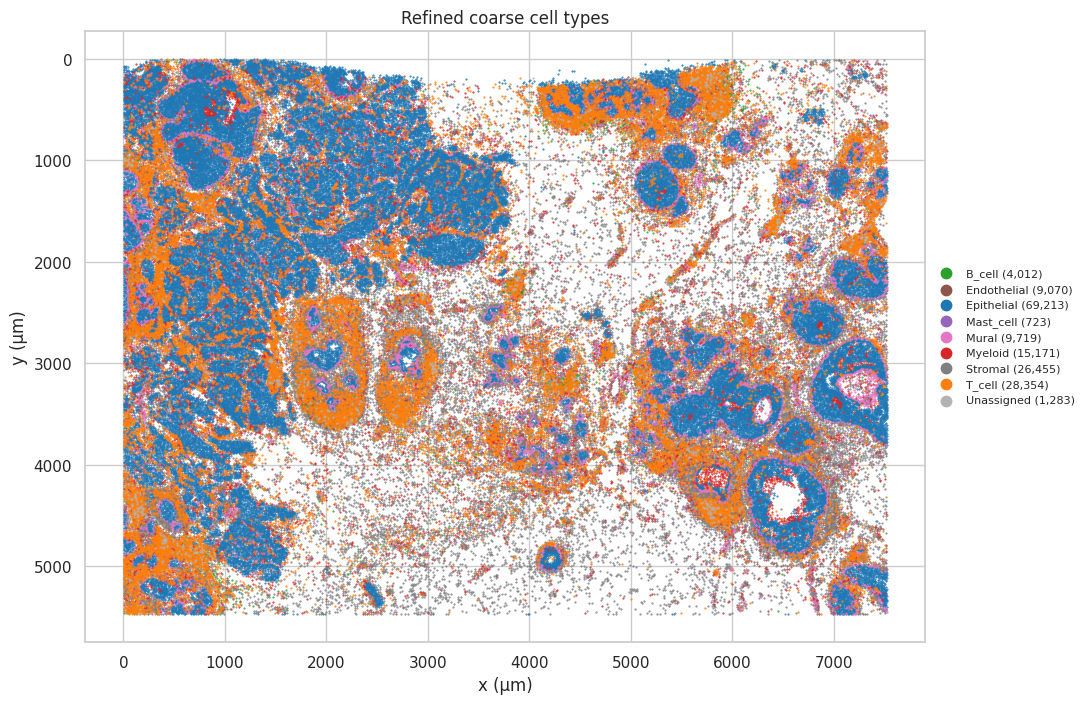

In [5]:
PAL = dict(zip(ALL_TYPES, sns.color_palette("tab10", n_colors=len(TYPES)) + [(0.7, 0.7, 0.7)]))
def spatial_scatter(ax, xy, labels, palette, s=0.25, title=""):
    for lab in sorted(pd.unique(labels)):
        m = np.asarray(labels == lab)
        ax.scatter(xy[m, 0], xy[m, 1], s=s, color=palette[lab], label=f"{lab} ({m.sum():,})", rasterized=True)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_title(title); ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
    ax.legend(markerscale=15, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)

fig, ax = plt.subplots(figsize=(11, 8))
spatial_scatter(ax, xy, obs["cell_type"].values, PAL, title="Refined coarse cell types")
plt.tight_layout(); fig.savefig(FIG_DIR / "spatial_cell_types_refined.png", dpi=200, bbox_inches="tight"); plt.show()

## Part 2 — Spatial QC: how far apart are cells, and how many neighbors will each radius contain?

Convex-hull area: 41.09 mm2 | mean density: 3,991 cells/mm2
Nearest-neighbor distance (um) quantiles:
 0.01     4.63
0.05     5.68
0.25     7.67
0.50     9.48
0.75    11.77
0.95    18.25
0.99    26.24
Cells at exactly the same position as another cell: 0


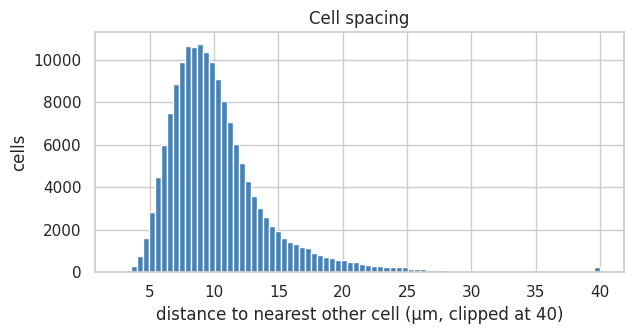

In [6]:
tree = cKDTree(xy)
d2, _ = tree.query(xy, k=2, workers=-1)
nn = d2[:, 1]
hull_area_mm2 = ConvexHull(xy).volume / 1e6
print(f"Convex-hull area: {hull_area_mm2:.2f} mm2 | mean density: {len(xy)/hull_area_mm2:,.0f} cells/mm2")
print("Nearest-neighbor distance (um) quantiles:\n", pd.Series(nn).quantile([.01, .05, .25, .5, .75, .95, .99]).round(2).to_string())
print("Cells at exactly the same position as another cell:", int((nn == 0).sum()))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.hist(np.clip(nn, 0, 40), bins=80, color="steelblue")
ax.set_xlabel("distance to nearest other cell (µm, clipped at 40)"); ax.set_ylabel("cells"); ax.set_title("Cell spacing")
plt.tight_layout(); fig.savefig(FIG_DIR / "nearest_neighbor_distance.png", dpi=200); plt.show()

## Part 3 — Unit tests: the neighborhood code is checked against brute force
This guards against silent bugs (self-inclusion, wrong ring edges, mixed-up indices) that would invalidate every later result.

In [7]:
codes_all = obs["cell_type"].map({t: i for i, t in enumerate(ALL_TYPES)}).values
onehot = np.eye(len(ALL_TYPES), dtype=np.float32)[codes_all]

test_rings = [(0, 15), (0, 30), (50, 100)]
stats_test = nbh.ring_stats(xy, onehot, test_rings, chunk=7000)       # small chunk size also tests chunk borders

sample = RNG.choice(len(xy), 300, replace=False)
for (r_in, r_out) in test_rings:
    for i in sample:
        dist = np.hypot(xy[:, 0] - xy[i, 0], xy[:, 1] - xy[i, 1])
        m = (dist >= r_in) & (dist <= r_out); m[i] = False
        assert stats_test[(r_in, r_out)]["n"][i] == m.sum(), (r_in, r_out, i)
        assert np.allclose(stats_test[(r_in, r_out)]["counts"][i], onehot[m].sum(0)), (r_in, r_out, i)
print("PASS: ring statistics match brute force for 300 random cells x 3 rings (self excluded).")

# nearest-type distance test
ti = TYPES.index("Epithelial")
dd = nbh.nearest_type_distance(xy, codes_all, ti)
for i in sample[:100]:
    m = codes_all == ti; m[i] = False
    assert np.isclose(dd[i], np.hypot(xy[m, 0] - xy[i, 0], xy[m, 1] - xy[i, 1]).min())
print("PASS: nearest-type distance matches brute force.")
del stats_test

PASS: ring statistics match brute force for 300 random cells x 3 rings (self excluded).
PASS: nearest-type distance matches brute force.


## Part 4 — Feature engineering
Every feature is computed **excluding the cell itself** and only from neighbors **within 30 µm**. The target (Part 6) uses only cells at **50–100 µm**, so the two never share a cell.

| Group | Features |
|---|---|
| composition | fraction of each coarse type (+ Unassigned) within 15 and 30 µm |
| density | neighbor count and cells/mm² within each radius |
| diversity | Shannon entropy and dominant-type fraction (assigned neighbors) |
| boundary | edge asymmetry = length of the mean unit vector to neighbors (≈0 in the interior, →1 at an edge or interface) |
| distance | mean distance to k nearest cells; distance to the nearest cell of each type |
| morphology | cell area, nucleus area, nucleus/cell ratio (intrinsic to the cell, kept separate) |

In [8]:
radii = TD["feature_neighborhood_radii_um"]
ta = tuple(TD["target_annulus_um"])
rings = [(0, r) for r in radii] + [ta]
stats = nbh.ring_stats(xy, onehot, rings)

feat, meta = {}, []
def add(name, values, group, definition, radius=None):
    feat[name] = np.asarray(values, dtype=np.float32)
    meta.append({"feature": name, "group": group, "radius_um": radius, "definition": definition})

for r in radii:
    st = stats[(0, r)]; n = st["n"].astype(np.float64); cnt = st["counts"]
    area = np.pi * (r / 1000) ** 2
    add(f"n_cells_r{r}", n, "density", f"cells within {r} um (self excluded)", r)
    add(f"density_r{r}", n / area, "density", f"cells per mm2 within {r} um", r)
    with np.errstate(divide="ignore", invalid="ignore"):
        frac = cnt / n[:, None]
    frac[n == 0] = np.nan
    for k, t in enumerate(ALL_TYPES):
        add(f"frac_{t}_r{r}", frac[:, k], "composition", f"fraction of neighbors within {r} um that are {t}", r)
    asg = cnt[:, :-1]; na = asg.sum(1)
    add(f"entropy_r{r}", nbh.shannon_entropy(asg), "diversity", f"Shannon entropy (nats) of assigned-type composition within {r} um", r)
    with np.errstate(divide="ignore", invalid="ignore"):
        dom = asg.max(1) / na
    dom[na == 0] = np.nan
    add(f"dominant_frac_r{r}", dom, "diversity", f"fraction of the most common assigned type within {r} um", r)
    with np.errstate(divide="ignore", invalid="ignore"):
        edge = np.hypot(st["vx"], st["vy"]) / n
        md_ = st["dsum"] / n
    edge[n == 0] = np.nan; md_[n == 0] = np.nan
    add(f"edge_asymmetry_r{r}", edge, "boundary", f"|mean unit vector to neighbors| within {r} um (0 = surrounded, 1 = one-sided)", r)
    add(f"mean_nbr_dist_r{r}", md_, "distance", f"mean distance to neighbors within {r} um", r)

kmax = max(N3["knn_ks"])
dk, _ = tree.query(xy, k=kmax + 1, workers=-1)
for k in N3["knn_ks"]:
    add(f"knn_dist_mean_k{k}", dk[:, 1:k + 1].mean(1), "distance", f"mean distance (um) to the {k} nearest cells")

for t in TYPES:
    add(f"dist_nearest_{t}", nbh.nearest_type_distance(xy, codes_all, TYPES.index(t)), "distance",
        f"distance (um) to the nearest other {t} cell")

ca = pd.to_numeric(obs["cell_area"], errors="coerce").values; na_ = pd.to_numeric(obs["nucleus_area"], errors="coerce").values
add("cell_area", ca, "morphology", "segmented cell area (um2)")
add("nucleus_area", na_, "morphology", "segmented nucleus area (um2)")
with np.errstate(divide="ignore", invalid="ignore"):
    add("nucleus_cell_area_ratio", na_ / ca, "morphology", "nucleus area / cell area")

F = pd.DataFrame(feat, index=obs.index)
FEATURE_META = pd.DataFrame(meta)
print("Feature table:", F.shape)
display(FEATURE_META.groupby("group").size().to_frame("n_features"))

Feature table: (164000, 43)


,n_features
group,
boundary,2
composition,18
density,4
distance,12
diversity,4
morphology,3


## Part 5 — Feature QC: missingness, scale, redundancy

,missing_frac,mean,std,min,max,n_unique
entropy_r15,0.1042,0.4600,0.4697,0.0000,1.9062,433
dominant_frac_r15,0.1042,0.7694,0.2399,0.1667,1.0000,78
frac_Epithelial_r15,0.1038,0.4677,0.4502,0.0000,1.0000,93
frac_Endothelial_r15,0.1038,0.0558,0.1598,0.0000,1.0000,60
frac_Mural_r15,0.1038,0.0666,0.1687,0.0000,1.0000,65
frac_Myeloid_r15,0.1038,0.0838,0.1819,0.0000,1.0000,75
frac_Mast_cell_r15,0.1038,0.0035,0.0401,0.0000,1.0000,27
frac_Stromal_r15,0.1038,0.1125,0.2319,0.0000,1.0000,64
frac_Unassigned_r15,0.1038,0.0079,0.0465,0.0000,1.0000,50
frac_B_cell_r15,0.1038,0.0253,0.0939,0.0000,1.0000,69


Constant features: none
Cells with 0 neighbors within 15um: 17016 | within 30um: 880
Median neighbors: r15=4, r30=18
Highly redundant pairs (|rho|>0.95): 5
   n_cells_r15 ~ density_r15 (1.00)
   entropy_r15 ~ dominant_frac_r15 (-0.98)
   n_cells_r30 ~ density_r30 (1.00)
   entropy_r30 ~ dominant_frac_r30 (-0.96)
   knn_dist_mean_k5 ~ knn_dist_mean_k10 (0.97)


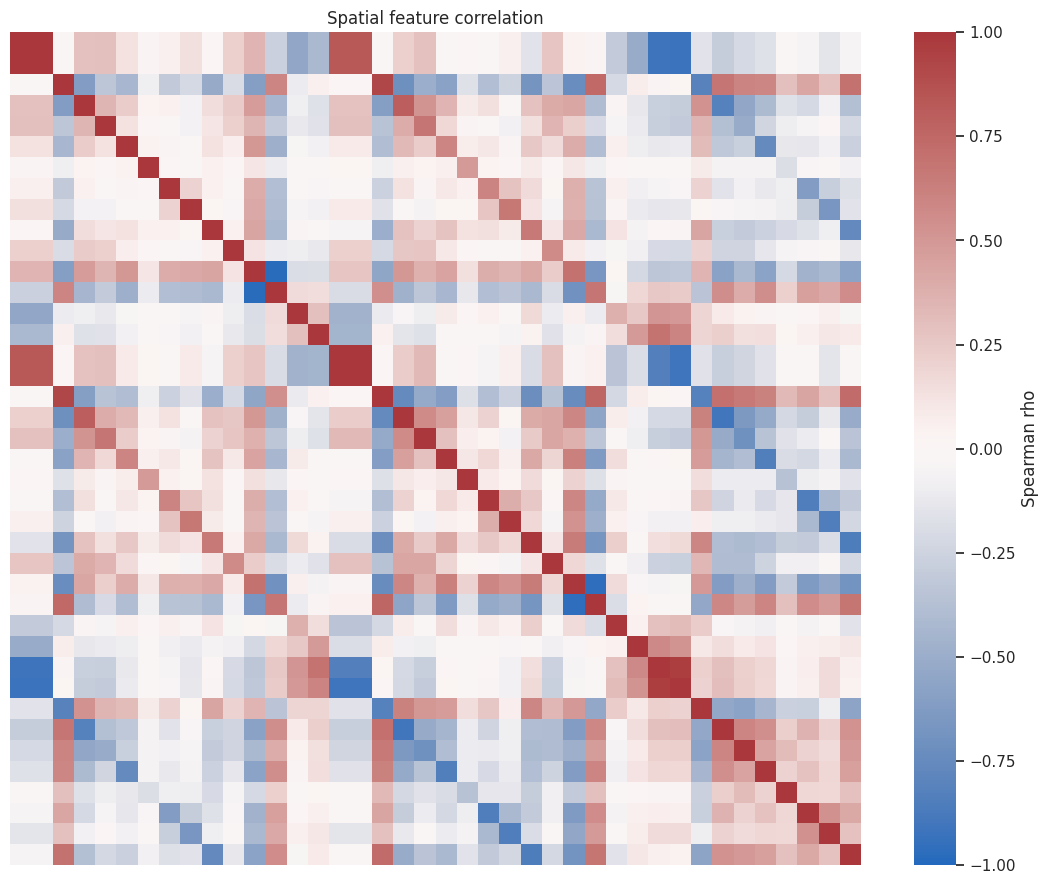

In [9]:
qc = pd.DataFrame({"missing_frac": F.isna().mean(), "mean": F.mean(), "std": F.std(), "min": F.min(), "max": F.max(), "n_unique": F.nunique()})
display(qc.sort_values("missing_frac", ascending=False).head(12).round(4))
const = qc.index[qc["n_unique"] <= 1].tolist()
print("Constant features:", const if const else "none")
print("Cells with 0 neighbors within 15um:", int((F['n_cells_r15'] == 0).sum()), "| within 30um:", int((F[f'n_cells_r{radii[-1]}'] == 0).sum()))
print(f"Median neighbors: r{radii[0]}={F[f'n_cells_r{radii[0]}'].median():.0f}, r{radii[-1]}={F[f'n_cells_r{radii[-1]}'].median():.0f}")
qc.round(5).to_csv(TAB_DIR / "feature_qc.csv")

# Redundancy among spatial features (Spearman on a subsample)
spat_cols = [c for c in FEATURE_META.loc[FEATURE_META["group"] != "morphology", "feature"] if qc.loc[c, "n_unique"] > 1]
sub = F[spat_cols].dropna()
sub = sub.sample(min(30000, len(sub)), random_state=SEED)
rho = pd.DataFrame(spearmanr(sub.values).statistic, index=spat_cols, columns=spat_cols)
pairs = [(a, b, rho.loc[a, b]) for i, a in enumerate(spat_cols) for b in spat_cols[i + 1:] if abs(rho.loc[a, b]) > 0.95]
print(f"Highly redundant pairs (|rho|>0.95): {len(pairs)}")
for p in pairs[:15]: print("  ", p[0], "~", p[1], f"({p[2]:.2f})")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(rho, cmap="vlag", center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False, ax=ax, cbar_kws={"label": "Spearman rho"})
ax.set_title("Spatial feature correlation")
plt.tight_layout(); fig.savefig(FIG_DIR / "feature_correlation.png", dpi=200); plt.show()

## Part 6 — The target: microenvironment class from the 50–100 µm annulus
For each cell we take the composition of **assigned cells in a 50–100 µm ring**, apply a Hellinger transform (square root of fractions, so rare types are not ignored), and cluster with k-means. `k` is chosen by **silhouette and split-half stability**, not by intuition. The classes are then named from their mean composition.

Cells with enough annulus context (>= 10 assigned cells): 163,122 (99.5%)


,k,silhouette,split_half_ARI
0,3,0.339,0.979
1,4,0.332,0.986
2,5,0.259,0.973
3,6,0.240,0.950
4,7,0.234,0.968
5,8,0.217,0.942


Chosen k = 3 (best silhouette 0.339; smallest stable k within 0.02 of it)


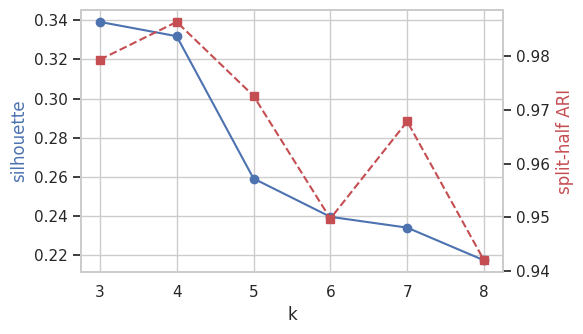

In [10]:
st = stats[ta]; cnt = st["counts"]
n_ann = st["n"]; n_asg = cnt[:, :-1].sum(1)
MINC = TD["min_cells_in_annulus"]
valid = (n_ann >= MINC) & (n_asg >= MINC)
print(f"Cells with enough annulus context (>= {MINC} assigned cells): {valid.sum():,} ({valid.mean():.1%})")

with np.errstate(divide="ignore", invalid="ignore"):
    ann_frac = cnt[:, :-1] / n_asg[:, None]
ann_frac[~valid] = np.nan
H = np.sqrt(np.nan_to_num(ann_frac))

vidx = np.where(valid)[0]
sub = RNG.choice(vidx, min(30000, len(vidx)), replace=False)
perm = RNG.permutation(vidx); third = len(perm) // 3
ia, ib, ic = perm[:third], perm[third:2 * third], perm[2 * third:2 * third + 20000]

rows = []
for k in N3["target_k_range"]:
    km = KMeans(k, n_init=5, random_state=SEED).fit(H[sub])
    sil = silhouette_score(H[sub], km.labels_, sample_size=10000, random_state=SEED)
    ka = KMeans(k, n_init=5, random_state=1).fit(H[ia]); kb = KMeans(k, n_init=5, random_state=2).fit(H[ib])
    ari = adjusted_rand_score(ka.predict(H[ic]), kb.predict(H[ic]))
    rows.append({"k": k, "silhouette": sil, "split_half_ARI": ari})
ksel = pd.DataFrame(rows); display(ksel.round(3)); ksel.round(4).to_csv(TAB_DIR / "target_k_selection.csv", index=False)

ok = ksel[ksel["split_half_ARI"] >= N3["target_min_stability_ari"]]
pool = ok if len(ok) else ksel
best = pool["silhouette"].max()
K = int(pool[pool["silhouette"] >= best - 0.02]["k"].min())      # parsimony: smallest stable k within 0.02 of the best silhouette
print(f"Chosen k = {K} (best silhouette {best:.3f}; smallest stable k within 0.02 of it)" + ("" if len(ok) else "  [no k met the stability threshold]"))

fig, ax = plt.subplots(figsize=(6, 3.5)); ax2 = ax.twinx()
ax.plot(ksel["k"], ksel["silhouette"], "o-", color="C0"); ax2.plot(ksel["k"], ksel["split_half_ARI"], "s--", color="C3")
ax.set_xlabel("k"); ax.set_ylabel("silhouette", color="C0"); ax2.set_ylabel("split-half ARI", color="C3"); ax2.grid(False)
plt.tight_layout(); fig.savefig(FIG_DIR / "target_k_selection.png", dpi=200); plt.show()

,n_cells,fraction_of_valid,Epithelial,T_cell,B_cell,Myeloid,Mast_cell,Endothelial,Mural,Stromal
ME1_Epithelial-rich,69389,0.425,0.769,0.050,0.001,0.049,0.001,0.041,0.040,0.047
ME2_Epithelial/T_cell,47603,0.292,0.330,0.210,0.017,0.104,0.005,0.064,0.102,0.167
ME3_T_cell/Stromal,46130,0.283,0.016,0.339,0.070,0.146,0.008,0.066,0.042,0.313


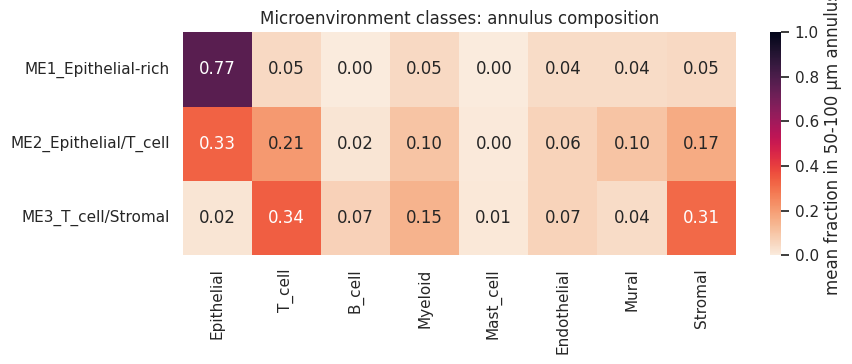

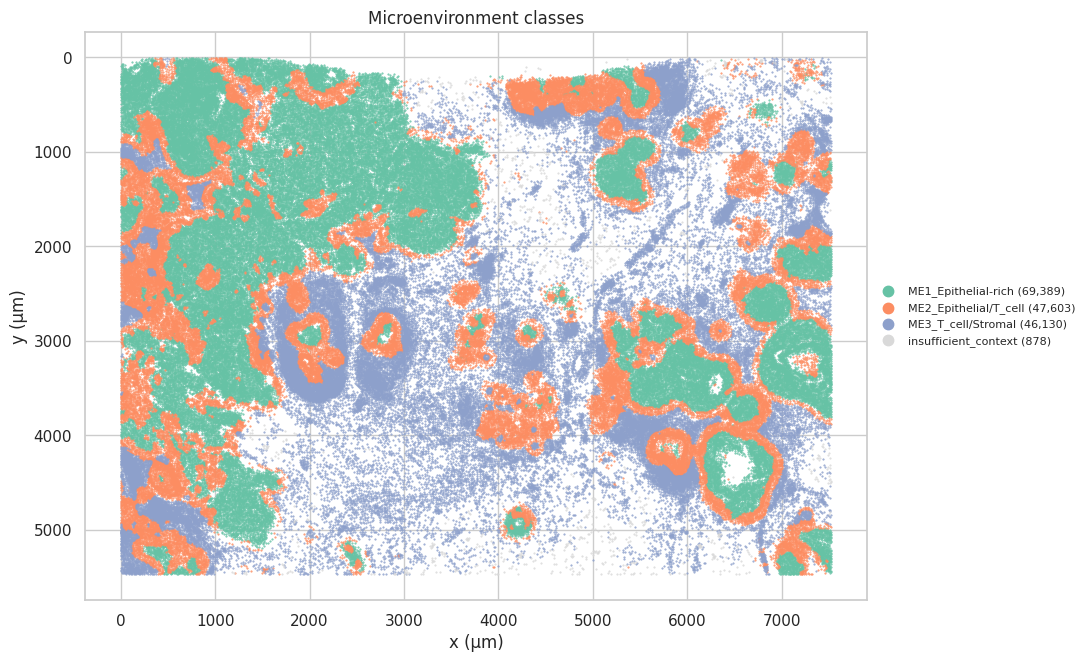

In [11]:
final = KMeans(K, n_init=10, random_state=SEED).fit(H[vidx])
raw = np.full(len(xy), -1); raw[vidx] = final.labels_

# name classes from their mean annulus composition; order by size
means = np.array([np.nanmean(ann_frac[raw == c], axis=0) for c in range(K)])
sizes = np.array([(raw == c).sum() for c in range(K)])
names = {}
for rank, c in enumerate(np.argsort(-sizes), start=1):
    o = np.argsort(-means[c]); t1, t2 = TYPES[o[0]], TYPES[o[1]]
    names[c] = f"ME{rank}_{t1}-rich" if means[c][o[0]] >= 0.55 else f"ME{rank}_{t1}/{t2}"
target = pd.Series(np.where(raw >= 0, pd.Series(raw).map(names), "insufficient_context"), index=obs.index, name="microenvironment_class")

prof = pd.DataFrame(means, index=[names[c] for c in range(K)], columns=TYPES)
prof.insert(0, "n_cells", sizes); prof.insert(1, "fraction_of_valid", sizes / sizes.sum())
prof = prof.sort_index(); display(prof.round(3)); prof.round(4).to_csv(TAB_DIR / "target_class_profiles.csv")

fig, ax = plt.subplots(figsize=(9, 0.6 * K + 2))
sns.heatmap(prof[TYPES], annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "mean fraction in 50-100 µm annulus"})
ax.set_title("Microenvironment classes: annulus composition")
plt.tight_layout(); fig.savefig(FIG_DIR / "target_class_composition.png", dpi=200); plt.show()

TPAL = dict(zip(sorted(prof.index), sns.color_palette("Set2", n_colors=K))); TPAL["insufficient_context"] = (0.85, 0.85, 0.85)
fig, ax = plt.subplots(figsize=(11, 8))
spatial_scatter(ax, xy, target.values, TPAL, title="Microenvironment classes")
plt.tight_layout(); fig.savefig(FIG_DIR / "spatial_microenvironment_classes.png", dpi=200, bbox_inches="tight"); plt.show()

In [12]:
# Is the target spatially coherent (real structure) rather than salt-and-pepper noise?
cls = raw.copy()
_, nbr = tree.query(xy, k=11, workers=-1); nbr = nbr[:, 1:]
nb_cls = cls[nbr]; ok_nb = nb_cls >= 0
same = ((nb_cls == cls[:, None]) & ok_nb).sum(1) / np.maximum(ok_nb.sum(1), 1)
obs_coh = same[valid].mean()
p = sizes / sizes.sum(); exp_coh = float((p ** 2).sum())
print(f"Same-class fraction among 10 nearest neighbors: observed {obs_coh:.3f} vs expected under random placement {exp_coh:.3f}  (x{obs_coh/exp_coh:.1f})")
print("Class balance:", dict(zip(prof.index, prof["n_cells"].astype(int))))
print("Smallest class share of valid cells: %.1f%%" % (100 * sizes.min() / sizes.sum()))

Same-class fraction among 10 nearest neighbors: observed 0.942 vs expected under random placement 0.346  (x2.7)
Class balance: {'ME1_Epithelial-rich': 69389, 'ME2_Epithelial/T_cell': 47603, 'ME3_T_cell/Stromal': 46130}
Smallest class share of valid cells: 28.3%


## Part 7 — Spatial cross-validation folds with a buffer
Cells are grouped into 500 µm blocks; blocks (not cells) are assigned to folds. For each test fold, training cells within **100 µm** of any test cell are dropped, so a test cell's target neighborhood never contains training cells that sit inside it.

,test_fold,n_test,n_train_after_buffer,n_dropped_by_buffer
0,0,32803,113896,17301
1,1,32800,111602,19598
2,2,32796,111402,19802
3,3,32804,111000,20196
4,4,32797,109956,21247


microenvironment_class,ME1_Epithelial-rich,ME2_Epithelial/T_cell,ME3_T_cell/Stromal
fold,,,
0,10601,11093,10980
1,16083,10382,6152
2,13906,8650,10060
3,14449,7219,10924
4,14350,10259,8014


Every class has >= 50 cells in every test fold.


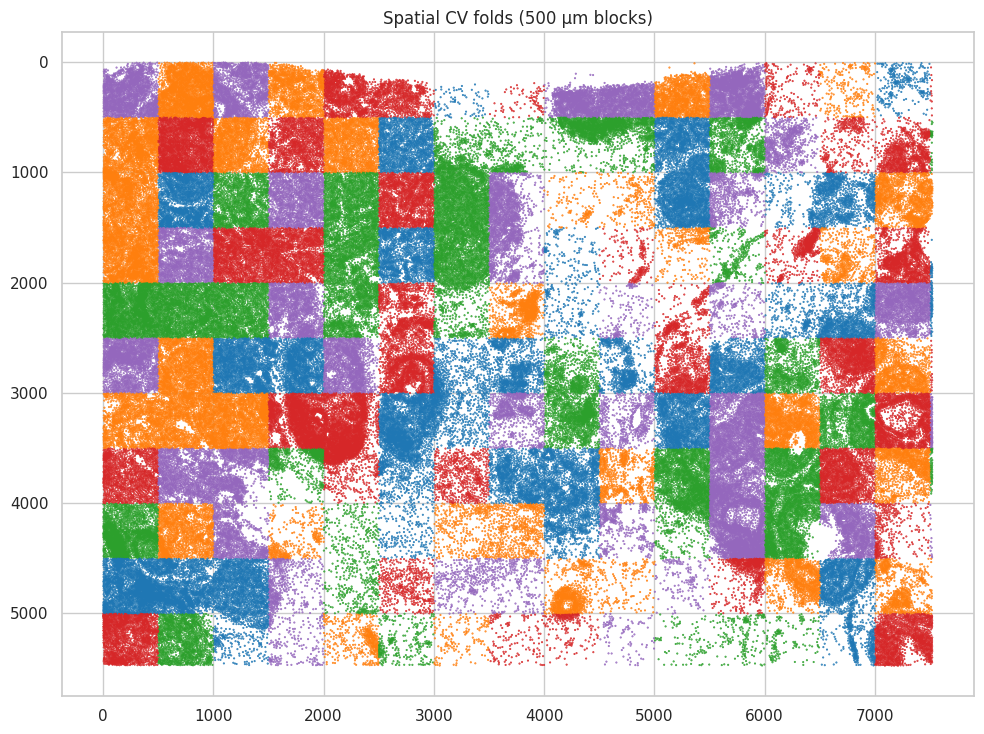

In [13]:
block, fold = nbh.make_spatial_folds(xy, TD["spatial_cv_block_size_um"], N3["spatial_cv_folds"], seed=SEED)
rows = []
for f in range(N3["spatial_cv_folds"]):
    tr, te = nbh.buffered_train_mask(xy, fold, f, TD["spatial_cv_buffer_um"])
    rows.append({"test_fold": f, "n_test": int(te.sum()), "n_train_after_buffer": int(tr.sum()),
                 "n_dropped_by_buffer": int((~te).sum() - tr.sum())})
fold_tab = pd.DataFrame(rows); display(fold_tab)
fold_tab.to_csv(TAB_DIR / "spatial_cv_folds_summary.csv", index=False)

ct_fold = pd.crosstab(pd.Series(fold, index=obs.index, name="fold")[valid], target[valid])
display(ct_fold)
low = (ct_fold < 50).sum().sum()
print("WARNING: some fold x class cells have < 50 samples." if low else "Every class has >= 50 cells in every test fold.")

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.scatter(xy[:, 0], xy[:, 1], c=fold, cmap="tab10", s=0.25, rasterized=True, vmin=0, vmax=9)
ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_title("Spatial CV folds (500 µm blocks)")
plt.tight_layout(); fig.savefig(FIG_DIR / "spatial_cv_folds.png", dpi=200); plt.show()

## Part 8 — Leakage audit and reference baselines

PASS: feature radii (<= 30 um) < target annulus start (50 um); self excluded; CV buffer (100 um) >= outer target radius (100 um).
Majority-class accuracy: 0.425 | chance balanced accuracy: 0.333
Own-cell-type lookup (in-sample, optimistic) balanced accuracy: 0.615


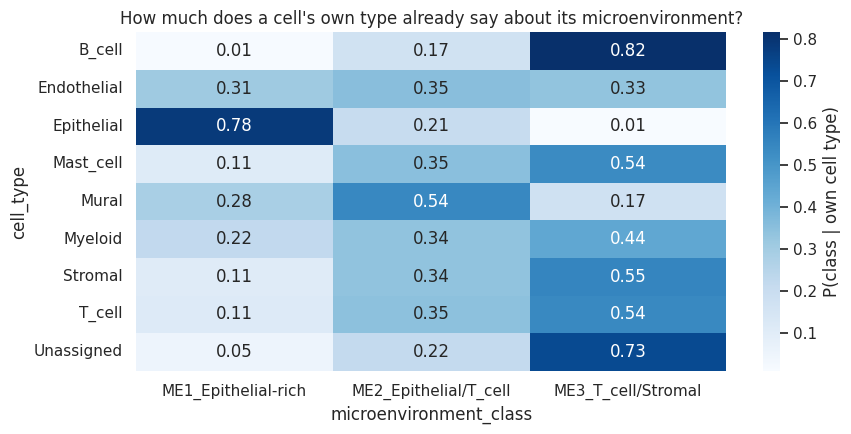

In [14]:
# Hard assertions: the design cannot silently drift
assert max(radii) < ta[0], "feature radii overlap the target annulus"
assert TD["spatial_cv_buffer_um"] >= ta[1], "CV buffer must be >= outer target radius"
assert not TD["feature_neighborhood_includes_self"]
assert all(c.startswith(("frac_", "n_cells", "density", "entropy", "dominant", "edge_", "mean_nbr", "knn_", "dist_nearest", "cell_area", "nucleus")) for c in F.columns)
assert "microenvironment_class" not in F.columns
print("PASS: feature radii (<= %d um) < target annulus start (%d um); self excluded; CV buffer (%d um) >= outer target radius (%d um)."
      % (max(radii), ta[0], TD["spatial_cv_buffer_um"], ta[1]))

# Reference baselines the ML models must beat (Module 5/6)
v = target[valid]
maj = v.value_counts(normalize=True).iloc[0]
print(f"Majority-class accuracy: {maj:.3f} | chance balanced accuracy: {1/K:.3f}")

lookup = pd.crosstab(obs.loc[valid, "cell_type"], v)
pred = obs.loc[valid, "cell_type"].map(lookup.idxmax(axis=1))
print(f"Own-cell-type lookup (in-sample, optimistic) balanced accuracy: {balanced_accuracy_score(v, pred):.3f}")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(lookup.div(lookup.sum(1), axis=0), annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar_kws={"label": "P(class | own cell type)"})
ax.set_title("How much does a cell's own type already say about its microenvironment?")
plt.tight_layout(); fig.savefig(FIG_DIR / "own_type_vs_target.png", dpi=200); plt.show()

## Part 9 — Save deliverables

In [15]:
table = pd.concat([
    obs[["cell_id"]].assign(x=xy[:, 0], y=xy[:, 1]),
    obs[["cell_type", "cell_type_fine", "label_confidence"]].astype(str),
    F,
    target,
    pd.Series(valid, index=obs.index, name="target_valid"),
    pd.Series(block, index=obs.index, name="spatial_block"),
    pd.Series(fold, index=obs.index, name="cv_fold"),
], axis=1)

try:
    table.to_parquet(PROC_DIR / "features_cell_level.parquet", index=True); fmt = "parquet"
except Exception as e:
    print("parquet unavailable (%s); writing csv.gz" % type(e).__name__)
    table.to_csv(PROC_DIR / "features_cell_level.csv.gz"); fmt = "csv.gz"

FEATURE_META.to_csv(TAB_DIR / "feature_dictionary.csv", index=False)
groups = FEATURE_META.groupby("group")["feature"].apply(list).to_dict()
groups["spatial_only"] = [f for g in ["composition", "density", "diversity", "boundary", "distance"] for f in groups[g]]
json.dump(groups, open(REP_DIR / "feature_groups.json", "w"), indent=2)
obs[["cell_id", "cell_type", "cell_type_fine"]].to_csv(TAB_DIR / "cell_types_refined.csv.gz", index=False)

CONFIG["notebook03"].update({"chosen_k": K, "classes": list(prof.index)})
json.dump(CONFIG, open(PROJECT_DIR / "configs/config.json", "w"), indent=2)

report = {
    "n_cells": int(len(table)), "n_features": int(F.shape[1]), "feature_table_format": fmt,
    "coarse_types": TYPES, "fraction_unassigned": float((obs["cell_type"] == "Unassigned").mean()),
    "target_k": K, "target_valid_cells": int(valid.sum()), "target_classes": list(prof.index),
    "target_spatial_coherence_ratio": float(obs_coh / exp_coh),
    "majority_baseline_accuracy": float(maj), "chance_balanced_accuracy": float(1 / K),
    "feature_radii_um": radii, "target_annulus_um": list(ta),
    "cv": {"block_um": TD["spatial_cv_block_size_um"], "buffer_um": TD["spatial_cv_buffer_um"], "folds": N3["spatial_cv_folds"]},
    "leakage_checks": "passed (radius < annulus, self excluded, buffer >= outer radius, brute-force unit tests)",
}
json.dump(report, open(REP_DIR / "notebook_03_report.json", "w"), indent=2)
print(json.dumps(report, indent=2))

{
  "n_cells": 164000,
  "n_features": 43,
  "feature_table_format": "parquet",
  "coarse_types": [
    "Epithelial",
    "T_cell",
    "B_cell",
    "Myeloid",
    "Mast_cell",
    "Endothelial",
    "Mural",
    "Stromal"
  ],
  "fraction_unassigned": 0.007823170731707317,
  "target_k": 3,
  "target_valid_cells": 163122,
  "target_classes": [
    "ME1_Epithelial-rich",
    "ME2_Epithelial/T_cell",
    "ME3_T_cell/Stromal"
  ],
  "target_spatial_coherence_ratio": 2.720949051945929,
  "majority_baseline_accuracy": 0.42538100317553734,
  "chance_balanced_accuracy": 0.3333333333333333,
  "feature_radii_um": [
    15,
    30
  ],
  "target_annulus_um": [
    50,
    100
  ],
  "cv": {
    "block_um": 500,
    "buffer_um": 100,
    "folds": 5
  },
  "leakage_checks": "passed (radius < annulus, self excluded, buffer >= outer radius, brute-force unit tests)"
}


## Checklist before Notebook 04 (statistics) and 05 (ML)
- [ ] Unit tests passed; leakage audit passed
- [ ] Refinement table: ambiguous clusters resolved only where biologically compatible; remaining Unassigned is small
- [ ] Class profiles are interpretable (each class has a recognizable dominant composition)
- [ ] Spatial coherence ratio is well above 1 (classes are real regions, not noise)
- [ ] Every class appears in every test fold; none is a tiny fraction of cells
- [ ] Note the **own-type lookup baseline**: your ML models must clearly beat it to claim spatial features add information